# Case Study 13 — Can a Mobile Phone Footprint Replace a Credit Bureau Score? AUC Comparison, DeLong Tests and Reject Inference

**Priority:** ★★★ Must-visit · **Reference:** Case Study 13 — *Unnamed Indian fintech lender (ISB / IIM Bangalore research): Financial Inclusion and Alternate Credit Scoring for the Millennials* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Chief Risk Officer, Head of Credit Policy, Product (onboarding), Legal & Compliance
**Data:** ⚠️ **SYNTHETIC** (D-13-01), calibrated to the paper's published statistics. The lender's data is private.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs13_alternate_data_credit_scoring.ipynb`

## 0. Executive Summary for Business

*(Synthetic data calibrated to the ISB/IIMB paper's published statistics; written after the analysis.)*

- **The question:** for young, thin-file applicants, does a phone footprint predict default better than the credit bureau? And could we safely approve people we currently reject?
- **Data source ranking (out-of-sample AUC, DeLong-tested):** bureau only **0.57** → financial **0.57** → phone footprint **0.60** → footprint + call logs **0.70** → everything **0.72**. Every step is statistically significant (Holm p < 0.01). This reproduces the paper's ordering (59% → 60% → 66% → 74%). For this segment, *behaviour* beats *credit history*.
- **The catch:** **call logs carry most of the gain**, and RBI's 2022 Digital Lending Guidelines **prohibit lending apps from accessing call logs and contacts**. With only today's permissible data (financial + consented footprint), AUC is **0.62**: still significantly better than bureau alone (+0.05), but much smaller.
- **Counterfactual approvals:** with all features, **21% of denied applicants** score below 10% predicted default and would have defaulted only **7.0%** of the time, half the current book's 14.7%. With permissible data alone, only 3.6% qualify.
- **Profitability is not the same as "safer than the book":** with 6% revenue and 80% loss-given-default per loan, break-even default is about 7%. Approving everyone below 10% PD is roughly break-even (≈ −₹2.6 lakh per 1 lakh applications). **Below 5% PD it earns ≈ +₹6 lakh.** Thresholds must come from unit economics.
- **Reject inference:** because the old policy used only observed variables, the model trained on approved applicants was already nearly unbiased for the denied (+0.5 pp). The popular "hard-cutoff augmentation" shortcut **over-states their risk by 21 pp**, and would wrongly keep them rejected.
- **I recommend:** do not use call logs or contacts. Build the thin-file model on consented **Account-Aggregator bank data + footprint signals with legal sign-off**, set the approval threshold at the economic break-even (≈ 5–7% PD), and validate with a small, capped randomised test-approve programme.

## 1. The Problem in Simple English

Priya is 24, works at a startup in Pune and wants a ₹20,000 loan for 60 days. She has never had a credit card or a loan, so the credit bureau knows almost nothing about her. Her "score" is weak or missing. A traditional lender says no. Millions of young Indians are in the same position.

Yet Priya's phone says a lot: she has LinkedIn and travel apps, she does not have five other instant-loan apps installed, and she makes and answers calls regularly. Research on real Indian fintech data found that this **digital footprint predicted default better than the bureau score** for such applicants.

The business wants to know:
1. **Which data source predicts default best**, and is the difference real or noise?
2. **How many currently rejected applicants could be approved safely**, given that we never observed what would have happened to them?
3. **Is it legal and wise** to use this data today?

## 2. Reference from the Case File

### (a) What the study found — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | "Young, thin-file applicants are rejected because bureau scores are weak or missing." |
| Question | "Does a phone footprint (installed apps, call logs, social logins) predict default better than the bureau score? How many rejected applicants could safely be approved?" |
| Data | "417,578 (Feb 2016–Nov 2018); 272,931 approved, 144,647 denied"; loans "₹10,000–₹200,000; 15–180 days; average ₹22,174"; "Average CIBIL 634"; mobile footprint (apps: Facebook, LinkedIn, financial, dating, e-commerce, travel, other loan apps; counts of calls, SMS, contacts; iOS vs Android); social login "Facebook (27%), LinkedIn (2.1%)"; call logs; "Default (~13.5%)" |
| Approach | "Logit models (explanatory). Out-of-sample ML. Comparison of feature sets by AUC. A prediction-based counterfactual (Kleinberg/Athey style) for denied applicants." |
| ML | Logit, **Random Forest**, **XGBoost**; out-of-sample validation |
| Metrics (AUC) | "Bureau score alone: **59%**; Mobile/social footprint alone: **60.4%**; Footprint + call logs: **66%**; Out of sample: deep mobile footprint **74%** vs deep financial information **59%**" |
| Impact (counterfactual) | "At a 10% (1%) predicted-default threshold, 'about **42% (22%)** borrowers who were denied credit would have been granted loans'." |
| Interpretation note | "Use of consented alternate data must follow RBI's Digital Lending Directions and the DPDP Act." |

**Source:** Agarwal, Alok, Ghosh & Gupta, *Financial Inclusion and Alternate Credit Scoring for the Millennials*, SSRN 3507827 (2019; revised 2023) — https://papers.ssrn.com/sol3/papers.cfm?abstract_id=3507827

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 150,000 applications (Jan 2023 – Dec 2024); bureau (22% thin-file), financial, footprint and call-log families; a historical approval policy (bureau + income) approving ≈ 67% |
| Hidden truth | Because it is a simulation, we also know what *denied* applicants would have done. That lets us **validate reject-inference methods**, which is impossible on real data |
| Statistics added | Chi-square / Mann–Whitney screening (Holm), explanatory logit with ORs, **DeLong tests for correlated AUCs**, likelihood-ratio tests of incremental value, inverse-probability-of-approval weighting, counterfactual approval analysis with Wilson CIs |
| Compliance lens | We separate features that are **permissible today** from those that are not (call logs and contacts are prohibited for lending apps under RBI's 2022 Digital Lending Guidelines) |

### (c) How the industry uses this

Thin-file underwriting is now mainstream in Indian digital lending. Today it uses *consented* bank-statement data via the **Account Aggregator** framework, GST data (Case 11), UPI transaction history (Case 16) and on-platform behaviour (MobiKwik, Case 15). The statistical toolkit here (feature-family AUC comparison with DeLong tests, and reject inference) is exactly how risk teams justify buying or building a new data source.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Should we add alternate data to underwriting thin-file applicants, and how many more could we approve? |
| Analytical 1 | Which feature families carry independent information about default (after controlling for the others)? |
| Analytical 2 | Are out-of-sample AUC differences between feature sets statistically real? |
| Analytical 3 | Does a model trained only on approved applicants mis-estimate the risk of denied applicants (selection bias), and can we correct it? |
| Analytical 4 | What share of denied applicants falls below a given predicted-default threshold, and how do they actually perform? |

**Hypotheses**
- **H1:** H0: AUC(set A) = AUC(set B) for each pair of feature sets (DeLong, paired on the same test applicants; Holm).
- **H2:** H0: adding the footprint (and call-log) families to bureau + financial does not improve fit (likelihood-ratio test).
- **H3:** H0: the naive model's predicted default rate for denied applicants equals their true rate (simulation-only check).

**Primary metric:** out-of-sample **AUC** (as in the paper), with a DeLong 95% CI. **Business metric:** share of denied applicants approvable at a PD threshold, and their realised default rate. **Guardrail:** the default rate of newly approved applicants must not exceed the current book's rate (≈ 14%); regulatory permissibility of every feature.
**Unit:** application. **Decision rule:** adopt a new data family if it raises AUC significantly (DeLong p < 0.05 after Holm) **and** is permissible, consented and explainable.

In [1]:
import sys, warnings, importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| The study's lender data | Private (an academic data-sharing agreement); not downloadable. |
| Public alternate-data credit datasets (UCI, GitHub) | **None with phone-footprint features and Indian thin-file borrowers.** UCI German Credit (used as a cross-check in Case 11) has no digital-footprint fields. |
| Kaggle | Not used (no credentials; excluded by the brief). |
| **Decision** | Synthetic data calibrated to the paper's published shares and AUC ordering, plus hidden outcomes for denied applicants to *validate* reject inference (D-13-01). |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs13.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 13 (alternate-data credit scoring for thin-file millennials)
================================================================================================
THIS DATA IS SYNTHETIC. The study's lender data is private (SSRN 3507827).

150,000 small-ticket loan applications (Jan 2023 - Dec 2024) from young, thin-file applicants with
four feature families: bureau, "deep financial" (income, employment, existing EMIs), mobile/social
footprint (installed apps, social logins, OS) and deep call-log features. A historical approval
policy (bureau + income) approves ~65%; outcomes exist ONLY for approved loans in the observed data.
Because this is a simulation we also keep the hidden outcome of DENIED applicants, which lets the
notebook validate reject-inference methods - something real data never allows.

Calibration anchors (reference file, Case Study 13): 417,578 applications, 272,931 approved (65.4%);
loans Rs 10k-200k, 15-180 days, average Rs 22,174; average CIBIL 634; default ~13.5%; AUCs bureau 59%,
footprint 60.4%, footprint + call logs 66%, deep mobile 74% vs deep financial 59%; Facebook login 27%,
LinkedIn 2.1%. Loadings are tuned to reproduce that ordering (decision.md D-13-02).

Output: data/cs13/applications.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42
N = 150_000


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    qb, qf, qc, qs = (rng.normal(0, 1, N) for _ in range(4))     # latent: bureau-, footprint-, call-, financial-related
    app_date = pd.Timestamp("2023-01-01") + pd.to_timedelta(rng.integers(0, 730, N), unit="D")
    age = np.clip(np.round(rng.normal(28, 4.5, N)), 21, 45)
    thin = rng.random(N) < 0.22
    bureau = np.where(thin, np.nan, np.clip(np.round(634 + 55 * (0.75 * qb + 0.66 * rng.normal(0, 1, N))), 300, 900))
    income = np.round(np.exp(np.log(28_000) + 0.35 * (0.4 * qs + 0.92 * rng.normal(0, 1, N))), -2)
    emp = rng.choice(["salaried", "self-employed", "gig/freelance"], N, p=[0.62, 0.23, 0.15])
    existing_emi = np.round(np.clip(income * rng.beta(1.2, 6, N) * (1 - 0.15 * qs), 0, None), -2)
    # mobile / social footprint
    ios = rng.random(N) < expit(-2.1 + 0.5 * qf + 0.25 * np.log(income / 28_000))
    fb = rng.random(N) < expit(-1.0 + 0.10 * qf)
    li = rng.random(N) < expit(-4.2 + 0.75 * qf)
    n_fin_apps = rng.poisson(np.exp(0.8 + 0.15 * qf))
    n_loan_apps = rng.poisson(np.exp(0.4 - 0.45 * qf))
    dating = rng.random(N) < expit(-2.0 - 0.15 * qf)
    n_ecom = rng.poisson(np.exp(1.2 + 0.05 * qf))
    n_travel = rng.poisson(np.exp(-0.2 + 0.35 * qf))
    n_contacts = rng.poisson(np.exp(5.6 + 0.10 * qf + 0.2 * rng.normal(0, 1, N)))
    n_sms = rng.poisson(np.exp(4.0 - 0.05 * qf))
    # deep call logs
    out_min = np.round(np.exp(np.log(600) + 0.40 * qc + 0.5 * rng.normal(0, 1, N)))
    missed_ratio = np.round(np.clip(expit(-1.3 - 0.55 * qc + 0.4 * rng.normal(0, 1, N)), 0, 1), 3)
    distinct_called = rng.poisson(np.exp(3.4 + 0.25 * qc))
    night_share = np.round(np.clip(expit(-2.4 - 0.35 * qc + 0.4 * rng.normal(0, 1, N)), 0, 1), 3)
    amount = np.clip(np.round(np.exp(rng.normal(np.log(17_000), 0.6, N)), -2), 10_000, 200_000)
    tenure = rng.choice([15, 30, 60, 90, 120, 180], N, p=[0.10, 0.30, 0.20, 0.20, 0.10, 0.10])
    # true default (observed only if approved)
    z = (-2.20 - 0.50 * qb - 0.35 * qs - 0.60 * qf - 0.85 * qc + 0.25 * thin + 0.15 * (tenure >= 120)
         + 0.20 * np.log(amount / 17_000) + 0.4 * rng.normal(0, 1, N))
    default_true = (rng.random(N) < expit(z)).astype(int)
    # historical approval policy: bureau + income (it never saw the phone data)
    approve = np.where(thin, income >= 30_000, (bureau >= 590) & (income >= 18_000))
    approve = approve | (rng.random(N) < 0.05)                              # manual overrides
    df = pd.DataFrame({
        "application_id": [f"AP{i:07d}" for i in range(1, N + 1)], "application_date": app_date, "age": age,
        "bureau_score": bureau, "monthly_income_inr": income, "employment": emp, "existing_emi_inr": existing_emi,
        "loan_amount_inr": amount, "tenure_days": tenure,
        "os_ios": ios.astype(int), "facebook_login": fb.astype(int), "linkedin_login": li.astype(int),
        "n_financial_apps": n_fin_apps, "n_other_loan_apps": n_loan_apps, "has_dating_app": dating.astype(int),
        "n_ecommerce_apps": n_ecom, "n_travel_apps": n_travel, "n_contacts": n_contacts, "n_sms_30d": n_sms,
        "outgoing_call_minutes_30d": out_min, "missed_call_ratio": missed_ratio, "distinct_numbers_called_30d": distinct_called,
        "night_call_share": night_share,
        "approved": approve.astype(int),
        "defaulted": np.where(approve, default_true, np.nan),                  # observed label
        "_default_if_funded": default_true,                                    # hidden truth (simulation only)
    }).sort_values("application_date").reset_index(drop=True)
    # data-quality issues
    df.loc[df.sample(n=1500, random_state=seed).index, ["outgoing_call_minutes_30d", "missed_call_ratio", "distinct_numbers_called_30d", "night_call_share"]] = np.nan  # call-log permission denied
    df.loc[df.sample(n=60, random_state=seed + 1).index, "monthly_income_inr"] = 9_999_999        # placeholder income
    return df


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs13"), exist_ok=True)
    d = generate(); d.to_csv(os.path.join(here, "cs13", "applications.csv.gz"), index=False)
    print(len(d), "approval", round(d.approved.mean(), 3), "default among approved", round(d.defaulted.mean(), 3),
          "avg bureau", round(d.bureau_score.mean(), 1), "true default denied", round(d.loc[d.approved == 0, "_default_if_funded"].mean(), 3))

Overwriting data/generate_cs13.py


In [3]:
os.makedirs("data/cs13", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs13 as gen; importlib.reload(gen)
raw = gen.generate(seed=SEED); raw.to_csv("data/cs13/applications.csv.gz", index=False)
print(f"{len(raw):,} applications | approved {raw.approved.mean():.1%} | default among approved {raw.defaulted.mean():.1%} | "
      f"avg bureau {raw.bureau_score.mean():.0f} | thin-file {raw.bureau_score.isna().mean():.0%} | Facebook login {raw.facebook_login.mean():.0%} | LinkedIn {raw.linkedin_login.mean():.1%}")

150,000 applications | approved 66.7% | default among approved 14.4% | avg bureau 634 | thin-file 22% | Facebook login 27% | LinkedIn 1.9%


| Parameter | Value | Basis |
|---|---|---|
| Applications / approval | 150k; historical policy approves ≈ 67% (bureau ≥ 590 and income ≥ ₹18k, or thin-file with income ≥ ₹30k, plus 5% manual overrides) | **Documented** 65.4% approval; the policy rule is ours |
| Loans | ₹10k–2 lakh, 15–180 days, ≈ ₹20k average | **Documented** range and ≈ ₹22k average |
| Bureau | mean 634, 22% thin-file (no score) | **Documented** average CIBIL 634; thin-file share ours |
| Footprint shares | Facebook login ≈ 27%, LinkedIn ≈ 2%, iOS ≈ 12%, other loan apps, dating, travel, e-commerce, contacts, SMS | **Documented** feature list and social-login shares |
| Default | ≈ 14% among approved; ≈ 20% among denied (hidden) | **Documented** ~13.5% |
| Signal structure | four independent latent factors (bureau-, financial-, footprint-, call-related) tuned so out-of-sample AUC ordering matches the paper | **Documented** AUC ordering 59 → 60 → 66 → 74 |
| DQ issues | 1,500 applicants denied call-log permission (blank call features); 60 placeholder incomes (₹99,99,999) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
FAM = {"bureau": ["bureau_score"], "financial": ["monthly_income_inr", "employment", "existing_emi_inr"],
       "footprint": ["os_ios", "facebook_login", "linkedin_login", "n_financial_apps", "n_other_loan_apps", "has_dating_app", "n_ecommerce_apps", "n_travel_apps", "n_contacts", "n_sms_30d"],
       "call logs": ["outgoing_call_minutes_30d", "missed_call_ratio", "distinct_numbers_called_30d", "night_call_share"]}
dd = pd.DataFrame([(c, f) for f, cs in FAM.items() for c in cs] + [("loan_amount_inr, tenure_days, age", "application"), ("approved", "decision (historical policy)"),
                   ("defaulted", "outcome: observed ONLY if approved"), ("_default_if_funded", "hidden truth incl. denied (simulation only)")], columns=["field", "family"])
dd["permissible for a lending app today?"] = dd.family.map({"call logs": "No: RBI DLG 2022 prohibits call-log/contact access",
                                                            "footprint": "Restricted: needs explicit consent, purpose limitation and app-store policy review"}).fillna("Yes (with consent / KYC)")
dd.to_csv("data/cs13/data_dictionary.csv", index=False); dd

,field,family,permissible for a lending app today?
0,bureau_score,bureau,Yes (with consent / KYC)
1,monthly_income_inr,financial,Yes (with consent / KYC)
2,employment,financial,Yes (with consent / KYC)
3,existing_emi_inr,financial,Yes (with consent / KYC)
4,os_ios,footprint,"Restricted: needs explicit consent, purpose li..."
5,facebook_login,footprint,"Restricted: needs explicit consent, purpose li..."
6,linkedin_login,footprint,"Restricted: needs explicit consent, purpose li..."
7,n_financial_apps,footprint,"Restricted: needs explicit consent, purpose li..."
8,n_other_loan_apps,footprint,"Restricted: needs explicit consent, purpose li..."
9,has_dating_app,footprint,"Restricted: needs explicit consent, purpose li..."


## 5. Data Quality Checks

In [5]:
df = pd.read_csv("data/cs13/applications.csv.gz", parse_dates=["application_date"])
CALL = FAM["call logs"]
checks = {"duplicate application_id": int(df.application_id.duplicated().sum()),
          "placeholder income ₹99,99,999": int((df.monthly_income_inr >= 9_999_999).sum()),
          "call-log fields blank (permission denied)": int(df[CALL[0]].isna().sum()),
          "bureau blank (thin file)": int(df.bureau_score.isna().sum()),
          "outcome blank for approved (should be 0)": int((df.approved.eq(1) & df.defaulted.isna()).sum()),
          "outcome present for denied (should be 0)": int((df.approved.eq(0) & df.defaulted.notna()).sum())}
print(pd.Series(checks, name="rows").to_string())
perm = df[CALL[0]].isna()
print(f"\nDefault rate (approved) with vs without call-log permission: {df.loc[perm, 'defaulted'].mean():.1%} vs {df.loc[~perm, 'defaulted'].mean():.1%}")

duplicate application_id                         0
placeholder income ₹99,99,999                   60
call-log fields blank (permission denied)     1500
bureau blank (thin file)                     32880
outcome blank for approved (should be 0)         0
outcome present for denied (should be 0)         0

Default rate (approved) with vs without call-log permission: 11.3% vs 14.4%


In [6]:
df.loc[df.monthly_income_inr >= 9_999_999, "monthly_income_inr"] = np.nan
df["income_missing"] = df.monthly_income_inr.isna().astype(int)
df["call_perm_denied"] = df[CALL[0]].isna().astype(int)
df["thin_file"] = df.bureau_score.isna().astype(int)
train_mask = df.application_date < "2024-05-01"
med = df[train_mask].median(numeric_only=True)
for c in ["monthly_income_inr"] + CALL:
    df[c] = df[c].fillna(med[c])
df["bureau_f"] = df.bureau_score.fillna(med.bureau_score)
df["log_income"] = np.log(df.monthly_income_inr); df["emi_ratio"] = (df.existing_emi_inr / df.monthly_income_inr).clip(0, 2)
df["self_emp"] = (df.employment == "self-employed").astype(int); df["gig"] = (df.employment == "gig/freelance").astype(int)
df["log_out_min"] = np.log1p(df.outgoing_call_minutes_30d); df["log_contacts"] = np.log1p(df.n_contacts); df["log_sms"] = np.log1p(df.n_sms_30d)
df["log_amount"] = np.log(df.loan_amount_inr); df["long_tenure"] = (df.tenure_days >= 120).astype(int)
df["period"] = np.where(train_mask, "train (Jan 2023 – Apr 2024)", "test (May – Dec 2024)")
dq = pd.DataFrame([
    ("Placeholder income ₹99,99,999", checks["placeholder income ₹99,99,999"], "Set missing → train median + flag", "System default, not a real income"),
    ("Call-log permission denied", checks["call-log fields blank (permission denied)"], "Train median + flag `call_perm_denied`", "Applicant choice; the flag lets the model learn whether refusal itself carries signal"),
    ("Thin file (no bureau score)", checks["bureau blank (thin file)"], "Median + flag `thin_file`", "Missing by design for new-to-credit; the flag is a feature"),
    ("Outcome only for approved", "—", "Model on approved; reject inference in 7.5", "Selection: the core statistical problem of credit scoring"),
], columns=["issue", "rows", "treatment", "reason"])
print(df.groupby("period").agg(applications=("approved", "size"), approved=("approved", "sum"), default_rate=("defaulted", "mean"))); dq

                             applications  approved  default_rate
period                                                           
test (May – Dec 2024)               50071     33374        0.1470
train (Jan 2023 – Apr 2024)         99929     66632        0.1426


,issue,rows,treatment,reason
0,"Placeholder income ₹99,99,999",60,Set missing → train median + flag,"System default, not a real income"
1,Call-log permission denied,1500,Train median + flag `call_perm_denied`,Applicant choice; the flag lets the model lear...
2,Thin file (no bureau score),32880,Median + flag `thin_file`,Missing by design for new-to-credit; the flag ...
3,Outcome only for approved,—,Model on approved; reject inference in 7.5,Selection: the core statistical problem of cre...


**Observation:** 60 placeholder incomes (₹99,99,999) were set to missing and imputed with a flag; 32,880 thin-file applicants (22%) and 1,500 who refused call-log permission were imputed with flags. **The outcome exists only for approved applicants (66,632 in training, 33,374 in test)**. That is not a data error: it is the selection problem every credit model faces (Section 7.5). Interesting: approved applicants who refused call-log access defaulted *less* (11.3% vs 14.4%). In our generator refusal was random, so this is a chance pattern, which we will see survive even a Holm correction (7.1).

## 6. Exploratory Data Analysis

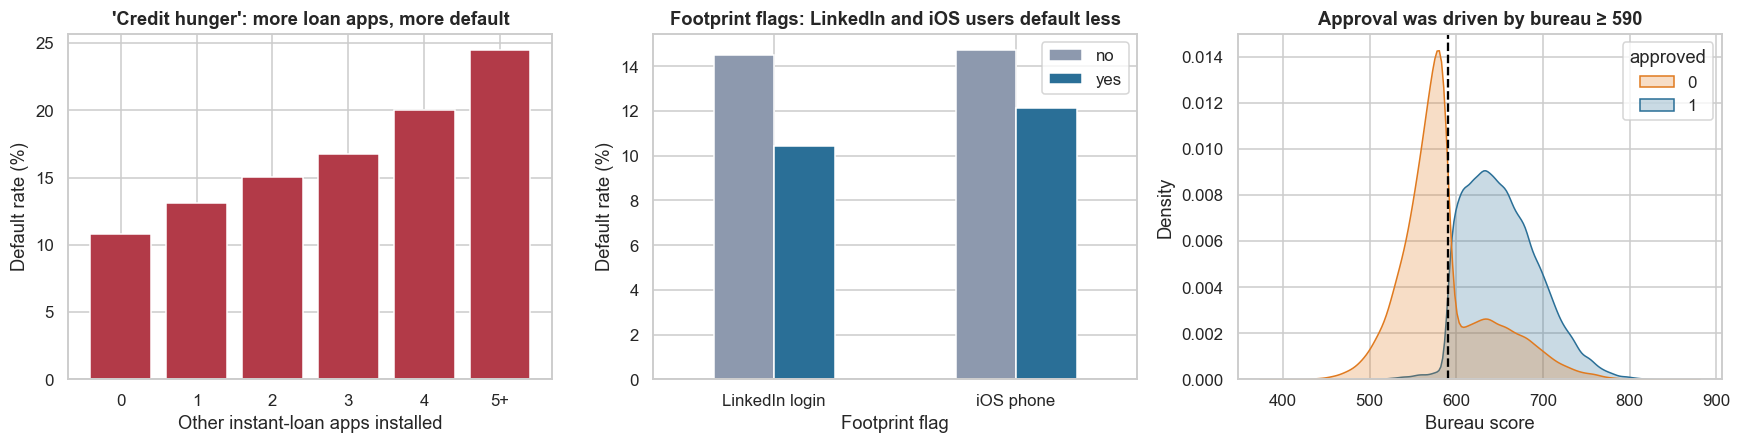

In [7]:
ap = df[df.approved == 1]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
r1 = ap.groupby(ap.n_other_loan_apps.clip(upper=5)).defaulted.agg(["mean", "size"])
axes[0].bar(r1.index.astype(str).str.replace("5", "5+"), r1["mean"] * 100, color="#b23a48")
axes[0].set_xlabel("Other instant-loan apps installed"); axes[0].set_ylabel("Default rate (%)"); axes[0].set_title("'Credit hunger': more loan apps, more default")
r2 = pd.DataFrame({"LinkedIn login": ap.groupby("linkedin_login").defaulted.mean(), "iOS phone": ap.groupby("os_ios").defaulted.mean()}).T * 100
r2.plot(kind="bar", ax=axes[1], color=["#8d99ae", "#2a6f97"]); axes[1].set_xlabel("Footprint flag"); axes[1].set_ylabel("Default rate (%)")
axes[1].set_title("Footprint flags: LinkedIn and iOS users default less"); axes[1].legend(["no", "yes"]); axes[1].tick_params(axis="x", rotation=0)
sns.kdeplot(data=df.dropna(subset=["bureau_score"]), x="bureau_score", hue="approved", common_norm=False, fill=True, ax=axes[2], palette={0: "#e07a1f", 1: "#2a6f97"})
axes[2].axvline(590, ls="--", color="black"); axes[2].set_xlabel("Bureau score"); axes[2].set_ylabel("Density"); axes[2].set_title("Approval was driven by bureau ≥ 590")
plt.tight_layout(); plt.show()

**Takeaway:** **left:** default climbs steadily with the number of *other* instant-loan apps installed (≈ 11% with none → ≈ 24% with 5+). This is the "credit hunger" signal the paper highlights. **Middle:** LinkedIn-login and iOS users default less (10–12% vs 14–15%), plausibly proxies for formal employment and income. **Right:** approval was driven by bureau ≥ 590. Approved and denied applicants differ systematically, which is the source of selection bias, and it also *restricts the range* of bureau scores among approved loans, one reason the bureau looks weak inside the approved book.

## 7. Statistical Analysis (core section)

### 7.1 Univariate screening (approved, training period)

**(a)** Binary flags → chi-square + phi. Numeric (skewed counts and ratios) → Mann–Whitney U + rank-biserial r (single-feature AUC = (1 + |r|)/2). **(e)** Holm across all features. **(b)** The training period only; outcomes exist only for approved applicants.

In [8]:
tr = df[train_mask & (df.approved == 1)]; te = df[~train_mask & (df.approved == 1)]
BIN = ["thin_file", "os_ios", "facebook_login", "linkedin_login", "has_dating_app", "self_emp", "gig", "call_perm_denied", "long_tenure"]
NUM = ["bureau_f", "log_income", "emi_ratio", "n_financial_apps", "n_other_loan_apps", "n_ecommerce_apps", "n_travel_apps", "log_contacts", "log_sms",
       "log_out_min", "missed_call_ratio", "distinct_numbers_called_30d", "night_call_share", "log_amount", "age"]
rows = []
for c in BIN:
    t = pd.crosstab(tr[c], tr.defaulted); c2, p, _, ex = stats.chi2_contingency(t, correction=False); rate = tr.groupby(c).defaulted.mean()
    rows.append((c, "chi-square", np.sqrt(c2 / len(tr)) * np.sign(rate.get(1, 0) - rate.get(0, 0)), p, f"{rate.get(0, np.nan):.1%} → {rate.get(1, np.nan):.1%}"))
for c in NUM:
    a_, b_ = tr.loc[tr.defaulted == 1, c], tr.loc[tr.defaulted == 0, c]; U, p = stats.mannwhitneyu(a_, b_)
    rows.append((c, "Mann–Whitney", 2 * U / (len(a_) * len(b_)) - 1, p, f"median {b_.median():.2f} (good) vs {a_.median():.2f} (bad)"))
scr = pd.DataFrame(rows, columns=["feature", "test", "effect (phi / r_rb)", "p", "detail"])
scr["p_holm"] = multipletests(scr.p, method="holm")[1]; scr["family"] = scr.feature.map(lambda f: next((k for k, v in {"bureau": ["bureau_f", "thin_file"], "financial": ["log_income", "emi_ratio", "self_emp", "gig"],
    "call logs": ["log_out_min", "missed_call_ratio", "distinct_numbers_called_30d", "night_call_share", "call_perm_denied"]}.items() if f in v), "footprint" if f not in ("log_amount", "age", "long_tenure") else "application"))
scr.sort_values("effect (phi / r_rb)", key=abs, ascending=False).round(4)

,feature,test,effect (phi / r_rb),p,detail,p_holm,family
20,distinct_numbers_called_30d,Mann–Whitney,-0.3123,0.0000,median 31.00 (good) vs 26.00 (bad),0.0000,call logs
19,missed_call_ratio,Mann–Whitney,0.3095,0.0000,median 0.21 (good) vs 0.27 (bad),0.0000,call logs
21,night_call_share,Mann–Whitney,0.2545,0.0000,median 0.08 (good) vs 0.10 (bad),0.0000,call logs
18,log_out_min,Mann–Whitney,-0.2448,0.0000,median 6.43 (good) vs 6.17 (bad),0.0000,call logs
13,n_other_loan_apps,Mann–Whitney,0.1398,0.0000,median 1.00 (good) vs 2.00 (bad),0.0000,footprint
9,bureau_f,Mann–Whitney,-0.1289,0.0000,median 640.00 (good) vs 634.00 (bad),0.0000,bureau
16,log_contacts,Mann–Whitney,-0.1264,0.0000,median 5.61 (good) vs 5.56 (bad),0.0000,footprint
17,log_sms,Mann–Whitney,0.0960,0.0000,median 4.01 (good) vs 4.04 (bad),0.0000,footprint
15,n_travel_apps,Mann–Whitney,-0.0890,0.0000,median 1.00 (good) vs 1.00 (bad),0.0000,footprint
12,n_financial_apps,Mann–Whitney,-0.0598,0.0000,median 2.00 (good) vs 2.00 (bad),0.0000,footprint


**Observation:** - **Call-log features show the largest effects** (|r_rb| 0.24–0.31): defaulters call fewer distinct numbers (26 vs 31 a month), miss more calls (27% vs 21%) and call more at night.
- **Footprint:** "other loan apps" is the strongest (r = 0.14), then contacts, travel and financial apps, then iOS (phi −0.024) and LinkedIn (−0.013).
- **Bureau and financial are weak** within the approved book (bureau r = −0.13; income −0.04). Range restriction explains part of this: everyone with a low bureau score was already rejected.
- **Not significant after Holm:** Facebook login (p_holm = 0.09), dating app, self-employed, gig work, age. So "being on Facebook" says nothing about creditworthiness here.
- **A warning about multiple testing:** the *call-log refusal* flag is significant after Holm (p_holm = 0.018), yet in our simulation refusal was assigned **at random**. With 24 tests, an occasional false positive survives even a correction. **Any surprising "signal" must be confirmed out of time before it goes into a credit policy.**

### 7.2 Explanatory logistic regression: odds ratios by family (the paper's "logit models")

**(a)** The paper first used logit models to ask which footprint variables matter *holding everything else constant*. Coefficients are reported as **odds ratios with 95% CIs**. Numeric features are standardised (per 1 SD), so their sizes are comparable across families. **(b)** Independence holds (one application per person); multicollinearity is low by design (the families are separate); with about 1,000 defaults per 10 parameters, events-per-variable is ample.

In [9]:
ALLF = BIN + NUM
Z = lambda d: (d[NUM] - tr[NUM].mean()) / tr[NUM].std()
trz = pd.concat([tr[BIN], Z(tr)], axis=1).assign(y=tr.defaulted.values)
logit = smf.logit("y ~ " + " + ".join(ALLF), data=trz).fit(disp=0)
ci = logit.conf_int()
orr = pd.DataFrame({"odds ratio": np.exp(logit.params), "CI low": np.exp(ci[0]), "CI high": np.exp(ci[1]), "p": logit.pvalues}).drop("Intercept")
orr["family"] = orr.index.map(scr.set_index("feature").family)
print(f"Pseudo-R² {logit.prsquared:.3f} | n = {int(logit.nobs):,} | events = {int(trz.y.sum()):,}")
orr.sort_values(["family", "p"]).round(3)

Pseudo-R² 0.095 | n = 66,632 | events = 9,499


,odds ratio,CI low,CI high,p,family
log_amount,1.0980,1.0740,1.1230,0.0000,application
long_tenure,1.1440,1.0820,1.2100,0.0000,application
age,1.0020,0.9800,1.0250,0.8300,application
bureau_f,0.7700,0.7520,0.7900,0.0000,bureau
thin_file,1.3600,1.2760,1.4480,0.0000,bureau
distinct_numbers_called_30d,0.7280,0.7040,0.7540,0.0000,call logs
missed_call_ratio,1.2840,1.2480,1.3200,0.0000,call logs
log_out_min,0.8670,0.8430,0.8910,0.0000,call logs
night_call_share,1.1310,1.1040,1.1590,0.0000,call logs
call_perm_denied,0.8210,0.6350,1.0620,0.1330,call logs


**(c)/(f) Observation:** holding all other families constant, **every call-log feature stays strong**: each +1 SD in distinct numbers called cuts default odds by 27% (OR 0.73), and each +1 SD in missed-call ratio raises them by 28%. From the footprint, **each +1 SD in other loan apps raises odds by 21%**, while contacts (OR 0.86) and travel apps (0.88) lower them. iOS: OR 0.90 (CI 0.83–0.97). **Bureau still matters** (OR 0.77 per SD; thin file ×1.36) and so does income (0.89). LinkedIn (p = 0.37) and Facebook (p = 0.16) lose significance once the rest is known: their univariate effect was a proxy for other footprint signals. The call-log refusal flag is *not* significant here (p = 0.13), which supports reading 7.1's result as chance. Pseudo-R² of 0.095 is typical for consumer credit.

### 7.3 Which data source predicts best? Out-of-sample AUC by feature set, with DeLong tests

**(a) Why DeLong?** All feature-set models are scored on **the same test applicants**, so their AUCs are *correlated*. Comparing their CIs separately would be wrong (too conservative). The **DeLong test** estimates the variance of the AUC *difference*, using the covariance between the two models' rankings. It is the standard test for comparing two ROC curves on the same data (D-13-04). We implement the fast O(n log n) version directly. **(e)** Holm across all pairwise comparisons.
**Sets** (each a logistic model trained on the training period, evaluated on May–Dec 2024 approved applicants):
1. Bureau only · 2. Financial (bureau + income, EMI, employment) · 3. Footprint only · 4. Call logs only · 5. Footprint + call logs ("deep mobile") · 6. **Permissible today** (financial + footprint, no call logs) · 7. All.

In [10]:
def midrank(x):
    J = np.argsort(x); Zs = x[J]; N = len(x); T = np.zeros(N); i = 0
    while i < N:
        j = i
        while j < N and Zs[j] == Zs[i]: j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1; i = j
    out = np.empty(N); out[J] = T; return out
def delong(y, preds):
    """Fast DeLong (Sun & Xu 2014): AUCs and covariance matrix for k correlated predictors."""
    y = np.asarray(y); pos, neg = preds[:, y == 1], preds[:, y == 0]; m, n = pos.shape[1], neg.shape[1]
    tx = np.array([midrank(p) for p in pos]); ty = np.array([midrank(q) for q in neg]); tz = np.array([midrank(np.r_[p, q]) for p, q in zip(pos, neg)])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1) / 2 / n
    v01 = (tz[:, :m] - tx) / n; v10 = 1 - (tz[:, m:] - ty) / m
    cov = np.atleast_2d(np.cov(v01)) / m + np.atleast_2d(np.cov(v10)) / n
    return aucs, cov
SETS = {"1 Bureau only": ["bureau_f", "thin_file"],
        "2 Financial": ["bureau_f", "thin_file", "log_income", "emi_ratio", "self_emp", "gig"],
        "3 Footprint only": ["os_ios", "facebook_login", "linkedin_login", "has_dating_app", "n_financial_apps", "n_other_loan_apps", "n_ecommerce_apps", "n_travel_apps", "log_contacts", "log_sms"],
        "4 Call logs only": ["log_out_min", "missed_call_ratio", "distinct_numbers_called_30d", "night_call_share", "call_perm_denied"]}
SETS["5 Footprint + call logs (deep mobile)"] = SETS["3 Footprint only"] + SETS["4 Call logs only"]
SETS["6 Permissible today (financial + footprint)"] = SETS["2 Financial"] + SETS["3 Footprint only"]
SETS["7 All"] = SETS["2 Financial"] + SETS["5 Footprint + call logs (deep mobile)"]
APPF = ["log_amount", "long_tenure"]
preds, models = [], {}
for n, f in SETS.items():
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(tr[f + APPF], tr.defaulted); models[n] = (m, f)
    preds.append(m.predict_proba(te[f + APPF])[:, 1])
P = np.vstack(preds); y_te = te.defaulted.values.astype(int)
aucs, cov = delong(y_te, P)
se = np.sqrt(np.diag(cov))
auc_t = pd.DataFrame({"AUC": aucs, "CI low": aucs - 1.96 * se, "CI high": aucs + 1.96 * se}, index=list(SETS))
auc_t["paper (documented)"] = ["59%", "≈59% ('deep financial')", "60.4%", "—", "66% / 74% OOS", "—", "—"]
names = list(SETS); pw = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        d_ = aucs[i] - aucs[j]; v = cov[i, i] + cov[j, j] - 2 * cov[i, j]; z = d_ / np.sqrt(v)
        pw.append((names[i], names[j], d_, 2 * stats.norm.sf(abs(z))))
pw = pd.DataFrame(pw, columns=["set A", "set B", "AUC A − B", "DeLong p"]); pw["p_holm"] = multipletests(pw["DeLong p"], method="holm")[1]
print(f"Test: {len(y_te):,} approved applicants, default rate {y_te.mean():.1%}")
display(auc_t.round(3))
pw[pw["set A"].str[0].isin(["1", "2", "5", "6"]) & pw["set B"].str[0].isin(["2", "3", "5", "6", "7"])].round(4)

Test: 33,374 approved applicants, default rate 14.7%


,AUC,CI low,CI high,paper (documented)
1 Bureau only,0.5660,0.5570,0.5740,59%
2 Financial,0.5710,0.5630,0.5800,≈59% ('deep financial')
3 Footprint only,0.6000,0.5910,0.6080,60.4%
4 Call logs only,0.6790,0.6710,0.6870,—
5 Footprint + call logs (deep mobile),0.7040,0.6960,0.7120,66% / 74% OOS
6 Permissible today (financial + footprint),0.6200,0.6120,0.6280,—
7 All,0.7150,0.7070,0.7220,—


,set A,set B,AUC A − B,DeLong p,p_holm
0,1 Bureau only,2 Financial,-0.0054,0.0029,0.0029
1,1 Bureau only,3 Footprint only,-0.0338,0.0000,0.0000
3,1 Bureau only,5 Footprint + call logs (deep mobile),-0.1380,0.0000,0.0000
4,1 Bureau only,6 Permissible today (financial + footprint),-0.0540,0.0000,0.0000
5,1 Bureau only,7 All,-0.1486,0.0000,0.0000
6,2 Financial,3 Footprint only,-0.0284,0.0000,0.0000
8,2 Financial,5 Footprint + call logs (deep mobile),-0.1327,0.0000,0.0000
9,2 Financial,6 Permissible today (financial + footprint),-0.0486,0.0000,0.0000
10,2 Financial,7 All,-0.1433,0.0000,0.0000
18,5 Footprint + call logs (deep mobile),6 Permissible today (financial + footprint),0.0841,0.0000,0.0000


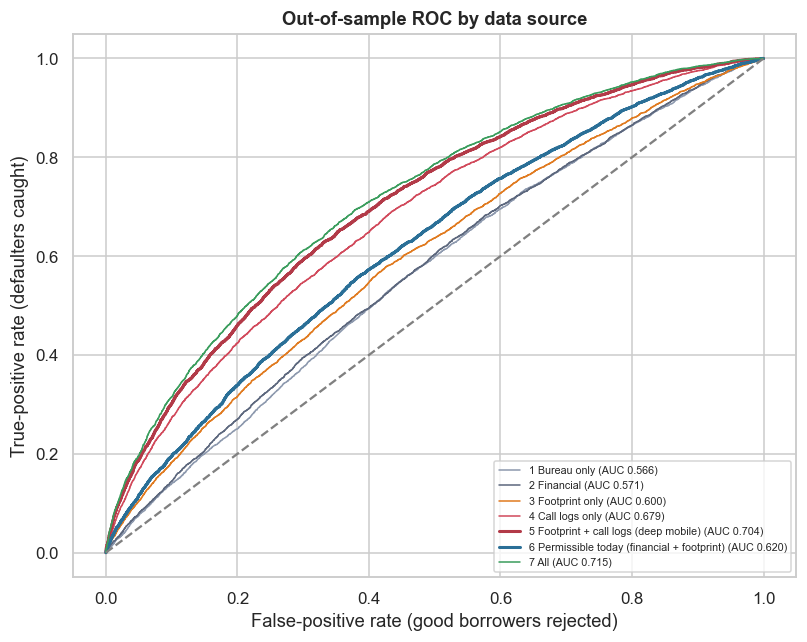

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 6))
pal = ["#8d99ae", "#5c677d", "#e07a1f", "#d1495b", "#b23a48", "#2a6f97", "#3a9d5d"]
for (n, _), p_, c in zip(SETS.items(), P, pal):
    f_, t_, _ = roc_curve(y_te, p_); ax.plot(f_, t_, color=c, lw=2 if n.startswith(("5", "6")) else 1, label=f"{n} (AUC {roc_auc_score(y_te, p_):.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey"); ax.set_xlabel("False-positive rate (good borrowers rejected)"); ax.set_ylabel("True-positive rate (defaulters caught)")
ax.set_title("Out-of-sample ROC by data source"); ax.legend(fontsize=7, loc="lower right"); plt.tight_layout(); plt.show()

**(c)/(f) Observation and takeaway:** - **Out-of-sample AUC (33,374 approved test applicants):** bureau **0.566** (CI 0.557–0.574) · financial **0.571** · footprint **0.600** · call logs alone **0.679** · footprint + call logs **0.704** · **permissible today 0.620** · all **0.715**.
- **DeLong tests (all Holm p < 0.01):** footprint beats bureau by +0.034 and financial by +0.028, matching the paper's headline that "mobile footprint ≥ bureau". Deep mobile (footprint + calls) beats financial by **+0.133**, the paper's "74% vs 59%" contrast. Even bureau → financial (+0.005) is statistically significant at this sample size, though practically negligible.
- **The compliance gap:** dropping call logs costs **0.085 AUC** (0.704 → 0.620 for the permissible set). Most of the paper's lift came from data a lending app may no longer collect.
- **For the business:** alternate data genuinely beats the bureau for thin-file millennials. But the *legally usable* gain today is about +0.05 AUC over the bureau, not +0.15. The data-source decision must be made on the permissible set.

### 7.4 Incremental value: nested likelihood-ratio tests

AUC asks "does it *rank* better?". The **likelihood-ratio test** asks "does the new family add information, *given* what we already have?". It compares a model with and without the family on the training data. **(H2)**

In [12]:
def lr_test(base, add):
    f0 = "y ~ " + " + ".join(base + APPF); f1 = "y ~ " + " + ".join(base + add + APPF)
    d = pd.concat([tr[BIN], Z(tr)], axis=1).assign(y=tr.defaulted.values, log_amount=Z(tr).log_amount, long_tenure=tr.long_tenure.values)
    m0, m1 = smf.logit(f0, data=d).fit(disp=0), smf.logit(f1, data=d).fit(disp=0)
    lr = 2 * (m1.llf - m0.llf); k = len(add)
    return lr, k, stats.chi2.sf(lr, k), m0.aic - m1.aic
inc = pd.DataFrame([("Financial + footprint vs financial", *lr_test(SETS["2 Financial"], SETS["3 Footprint only"])),
                    ("+ call logs vs financial + footprint", *lr_test(SETS["6 Permissible today (financial + footprint)"], SETS["4 Call logs only"])),
                    ("Financial vs bureau only", *lr_test(SETS["1 Bureau only"], ["log_income", "emi_ratio", "self_emp", "gig"]))],
                   columns=["comparison", "LR χ²", "df", "p", "AIC improvement"]).set_index("comparison")
inc.round(4)

,LR χ²,df,p,AIC improvement
comparison,,,,
Financial + footprint vs financial,"1,084.3714",10,0.0000,"1,064.3714"
+ call logs vs financial + footprint,"3,420.5068",5,0.0000,"3,410.5068"
Financial vs bureau only,100.5922,4,0.0000,92.5922


**Observation:** every nested comparison is overwhelmingly significant. Adding the footprint to financial data: LR χ² = 1,084 on 10 df. Adding call logs on top: χ² = 3,421 on 5 df, the largest information gain of any family. Adding income/EMI to bureau: χ² = 101 on 4 df, significant but small. **H2 is rejected at every step: each family adds information.** The likelihood-ratio results mirror the AUC ranking, so the conclusions do not depend on which yardstick we use.

### 7.5 Selection bias and reject inference: can we trust the model on people we rejected?

**(a) The core problem:** we only see outcomes for *approved* applicants. The historical policy approved on bureau ≥ 590 and income. Denied applicants are therefore systematically different, and a model trained on the approved may **mis-estimate their risk**. In real life this is untestable. In our simulation we hold the hidden truth, so we can check.
**Methods compared (D-13-05):**
1. **Naive:** train on approved only, score the denied.
2. **Inverse-probability-of-approval weighting (IPW):** model P(approved | x) on *all* applicants, then weight each approved loan by 1/P(approved). Approved applicants who "look like" denied ones get more weight. This is valid when approval depended only on observed variables (missing at random), which is true here because the policy used bureau and income plus random overrides.
3. **Hard-cutoff augmentation:** score the denied with the naive model, label those above the median predicted PD as "bad", refit on approved + augmented denied. A common industry shortcut.

**Check (H3):** compare each method's predicted mean default for denied applicants with their true default rate, plus AUC on the denied (truth).

In [13]:
X_all = df[SETS["7 All"] + APPF]; den = df[~train_mask & (df.approved == 0)]
naive = models["7 All"][0]
apm = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(df.loc[train_mask, ["bureau_f", "thin_file", "log_income"]], df.loc[train_mask, "approved"])
p_app = apm.predict_proba(tr[["bureau_f", "thin_file", "log_income"]])[:, 1]
ipw = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(tr[SETS["7 All"] + APPF], tr.defaulted, logisticregression__sample_weight=1 / np.clip(p_app, 0.05, 1))
den_tr = df[train_mask & (df.approved == 0)]
pd_den_tr = naive.predict_proba(den_tr[SETS["7 All"] + APPF])[:, 1]
aug_y = (pd_den_tr >= np.median(pd_den_tr)).astype(int)
aug = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(pd.concat([tr[SETS["7 All"] + APPF], den_tr[SETS["7 All"] + APPF]]), np.r_[tr.defaulted.values, aug_y])
truth_den = den._default_if_funded.values
ri = []
for n_, m_ in [("Naive (approved only)", naive), ("IPW (approval-weighted)", ipw), ("Hard-cutoff augmentation", aug)]:
    p_ = m_.predict_proba(den[SETS["7 All"] + APPF])[:, 1]
    ri.append((n_, p_.mean(), truth_den.mean(), p_.mean() - truth_den.mean(), roc_auc_score(truth_den, p_)))
ri = pd.DataFrame(ri, columns=["method", "predicted default (denied)", "TRUE default (denied, hidden)", "bias", "AUC on denied (truth)"]).set_index("method")
print(f"Approved test default {te.defaulted.mean():.1%} vs denied applicants' hidden true default {truth_den.mean():.1%}")
ri.round(4)

Approved test default 14.7% vs denied applicants' hidden true default 19.8%


,predicted default (denied),"TRUE default (denied, hidden)",bias,AUC on denied (truth)
method,,,,
Naive (approved only),0.2031,0.1977,0.0054,0.7063
IPW (approval-weighted),0.2040,0.1977,0.0063,0.7055
Hard-cutoff augmentation,0.4099,0.1977,0.2122,0.7012


**(c)/(f) Observation:** - **Denied applicants really are riskier:** a hidden true default rate of **19.8% vs 14.7%** for the approved test book. The old policy did select better risks.
- **The naive model is almost unbiased for them** (predicted 20.3% vs true 19.8%; AUC on the denied 0.71). The historical policy selected only on bureau and income, which the model also sees, and 5% random overrides gave it some exposure to "denied-looking" applicants. When selection is *on observables*, a well-specified model transfers.
- **IPW** gives essentially the same answer (+0.6 pp), as theory predicts in this case. It would matter more if the model omitted the selection variables.
- **Hard-cutoff augmentation is badly biased** (predicted 41% vs true 20%). Labelling half of the rejects "bad" by fiat bakes the old policy's prejudice into the new model, a common industry shortcut worth retiring.
- **Caveat:** in real data, selection often happens on *unobservables* (branch manager judgement, documents not in the system). Then no statistical correction is reliable, and only a randomised test-approve programme can tell.

### 7.6 The counterfactual: how many denied applicants could have been approved, and how would they have performed?

Following the paper's prediction-based counterfactual, we score the **denied** applicants of the test period with the IPW model (the best-calibrated in 7.5) and count how many fall below predicted-default thresholds of **10%** and **5%**. The paper reports 42% / 22% at 10% / 1%; our PD scale differs, so we use 10% / 5%. Because we hold the truth, we also report their **realised** default rate with Wilson CIs, a validation real lenders can only obtain through a small randomised "test-approve" programme.

In [14]:
p_den = ipw.predict_proba(den[SETS["7 All"] + APPF])[:, 1]
p_den_perm = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(tr[SETS["6 Permissible today (financial + footprint)"] + APPF], tr.defaulted,
            logisticregression__sample_weight=1 / np.clip(p_app, 0.05, 1)).predict_proba(den[SETS["6 Permissible today (financial + footprint)"] + APPF])[:, 1]
cf = []
for lab, p_ in [("All features incl. call logs", p_den), ("Permissible today (no call logs)", p_den_perm)]:
    for thr in (0.10, 0.05):
        sel = p_ < thr; k_ = int(truth_den[sel].sum()); lo, hi = proportion_confint(k_, max(sel.sum(), 1), method="wilson")
        cf.append((lab, f"PD < {thr:.0%}", sel.mean(), sel.sum(), truth_den[sel].mean() if sel.any() else np.nan, lo, hi))
cf = pd.DataFrame(cf, columns=["model", "threshold", "share of denied approvable", "applicants", "TRUE default of those", "CI low", "CI high"])
print(f"Benchmark: current approved book default (test period) = {te.defaulted.mean():.1%}")
cf.round(4)

Benchmark: current approved book default (test period) = 14.7%


,model,threshold,share of denied approvable,applicants,TRUE default of those,CI low,CI high
0,All features incl. call logs,PD < 10%,0.2061,3441,0.0700,0.0620,0.0791
1,All features incl. call logs,PD < 5%,0.0416,695,0.0417,0.0292,0.0593
2,Permissible today (no call logs),PD < 10%,0.0361,602,0.0781,0.0592,0.1023
3,Permissible today (no call logs),PD < 5%,0.0012,20,0.1500,0.0524,0.3604


**Observation:** - **All features:** 20.6% of denied test applicants (3,441) score below 10% PD, and their **true** default would have been **7.0% (CI 6.2–7.9%)**, half the approved book's 14.7%. Below 5% PD: 4.2% of the denied, with 4.2% true default.
- **Permissible features only:** just **3.6%** of the denied qualify at < 10% PD (true default 7.8%), and almost nobody at < 5%.
- **Versus the paper:** the documented "42% (22%)" approvable at 10% (1%) thresholds is larger than our 21%. Our synthetic PD distribution differs, but the *direction* is the same: a large minority of rejects is creditworthy on alternate data.
- **For the business:** the inclusion opportunity is real but **depends heavily on data you may not be allowed to use**.

## 8. ML Section — Random Forest and gradient boosting vs logistic (the paper's ML step)

The paper used Random Forest and XGBoost. To stay within the project's library list, we use scikit-learn's Random Forest and `HistGradientBoostingClassifier` (default settings, no tuning; D-13-06) on the "All" feature set, compared with logistic via DeLong. We then measure **family importance**: the drop in AUC when an *entire family's* columns are shuffled together (grouped permutation).

,AUC,Δ vs logistic,DeLong p vs logistic
Logistic,0.7146,0.0000,NaN
Random Forest,0.7086,-0.0060,0.0000
Gradient boosting,0.7091,-0.0055,0.0000


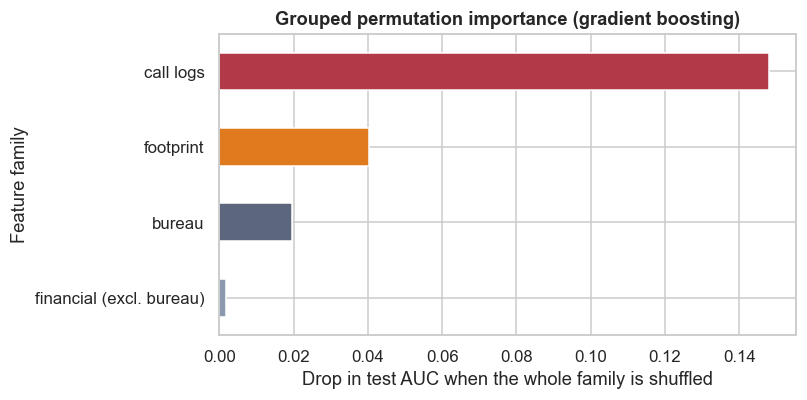

In [15]:
FALL = SETS["7 All"] + APPF
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=SEED).fit(tr[FALL], tr.defaulted)
gb = HistGradientBoostingClassifier(random_state=SEED).fit(tr[FALL], tr.defaulted)
P2 = np.vstack([models["7 All"][0].predict_proba(te[FALL])[:, 1], rf.predict_proba(te[FALL])[:, 1], gb.predict_proba(te[FALL])[:, 1]])
a2, c2_ = delong(y_te, P2)
mc = pd.DataFrame({"AUC": a2}, index=["Logistic", "Random Forest", "Gradient boosting"])
mc["Δ vs logistic"] = a2 - a2[0]
mc["DeLong p vs logistic"] = [np.nan] + [2 * stats.norm.sf(abs((a2[i] - a2[0]) / np.sqrt(c2_[i, i] + c2_[0, 0] - 2 * c2_[i, 0]))) for i in (1, 2)]
fam_imp = {}
base_auc = roc_auc_score(y_te, gb.predict_proba(te[FALL])[:, 1])
for fam, cols in {"bureau": SETS["1 Bureau only"], "financial (excl. bureau)": ["log_income", "emi_ratio", "self_emp", "gig"], "footprint": SETS["3 Footprint only"], "call logs": SETS["4 Call logs only"]}.items():
    drops = []
    for r_ in range(5):
        Xp = te[FALL].copy(); perm = np.random.default_rng(SEED + r_).permutation(len(Xp)); Xp[cols] = Xp[cols].values[perm]
        drops.append(base_auc - roc_auc_score(y_te, gb.predict_proba(Xp)[:, 1]))
    fam_imp[fam] = np.mean(drops)
fam_imp = pd.Series(fam_imp).sort_values()
display(mc.round(4))
fig, ax = plt.subplots(figsize=(7.5, 3.8)); fam_imp.plot(kind="barh", color=["#8d99ae", "#5c677d", "#e07a1f", "#b23a48"][:len(fam_imp)], ax=ax)
ax.set_xlabel("Drop in test AUC when the whole family is shuffled"); ax.set_ylabel("Feature family"); ax.set_title("Grouped permutation importance (gradient boosting)")
plt.tight_layout(); plt.show()

**Takeaway:** Random Forest (AUC 0.709) and gradient boosting (0.709) are both **slightly but significantly worse** than logistic regression (0.715; DeLong p < 0.001). The signal here is mostly additive, so flexible models add variance. The **grouped permutation importance** confirms the story: shuffling the **call-log family** costs about 0.15 AUC, the footprint about 0.04, the bureau about 0.02, and the remaining financial variables almost nothing. A lender that loses call-log access loses most of the model's edge.

## 9. Business Translation — what approving the "safe denied" is worth, and what compliance costs

**Logic (per 1 lakh applications, test-period mix):** newly approvable applicants = denied × share below the PD threshold. Per loan: average ticket ≈ ₹20,000; revenue on a good loan ≈ 6% of principal (fees + interest over a short tenure); loss on a defaulted loan ≈ 80% of principal (LGD for unsecured small-ticket loans). **Net = revenue on goods − loss on bads**, using the *true* outcomes from 7.6 (simulation). Assumptions in D-13-07; sensitivity: revenue 4–8%, LGD 70–90%.

In [16]:
den_share = (df.loc[~train_mask, "approved"] == 0).mean()
avg_amt = den.loan_amount_inr.mean()
def econ(sel, rev, lgd):
    n = sel.sum(); bad = truth_den[sel].sum(); amt = den.loan_amount_inr.values[sel]
    gain = (amt * (1 - truth_den[sel])).sum() * rev - (amt * truth_den[sel]).sum() * lgd
    return n, bad / max(n, 1), gain / len(den) * den_share * 100_000
rows = []
for lab, p_ in [("All features incl. call logs", p_den), ("Permissible today (no call logs)", p_den_perm)]:
    for thr in (0.10, 0.05):
        sel = p_ < thr
        for scen, rev, lgd in [("worst", 0.04, 0.9), ("base", 0.06, 0.8), ("best", 0.08, 0.7)]:
            n, br, g = econ(sel, rev, lgd)
            rows.append((lab, f"PD < {thr:.0%}", scen, br, sel.mean() * den_share * 100_000, g / 1e5))
biz = pd.DataFrame(rows, columns=["model", "threshold", "scenario", "true default", "extra loans per 1 lakh applications", "net ₹ lakh per 1 lakh applications"])
biz.pivot_table(index=["model", "threshold"], columns="scenario", values="net ₹ lakh per 1 lakh applications").round(2).join(
    biz[biz.scenario == "base"].set_index(["model", "threshold"])[["extra loans per 1 lakh applications", "true default"]].round(3))

base    best    worst  extra loans per 1 lakh applications  true default
model                            threshold                                                                            
All features incl. call logs     PD < 10%  -2.6300 30.9100 -36.1700                           6,872.2410        0.0700
                                 PD < 5%    6.0400 11.7600   0.3200                           1,388.0290        0.0420
Permissible today (no call logs) PD < 10%  -0.6100  4.5000  -5.7300                           1,202.2930        0.0780
                                 PD < 5%   -0.4000 -0.2300  -0.5800                              39.9430        0.1500

**Business reading:** - **All features, PD < 10%:** about 6,900 extra loans per 1 lakh applications, but their 7.0% default sits right at break-even (6% revenue vs 80% LGD → break-even ≈ 7%). Net ≈ **−₹2.6 lakh** (range −₹36 lakh to +₹31 lakh). Very sensitive to pricing.
- **All features, PD < 5%:** about 1,400 extra loans, 4.2% default, **net ≈ +₹6.0 lakh per 1 lakh applications** (₹0.3–11.8 lakh), positive in every scenario.
- **Permissible features only:** about 1,200 extra loans at < 10% PD, roughly break-even (−₹0.6 lakh). Almost none at < 5%.
- **Lesson:** "safer than our average book" is the wrong approval test. The right test is **"expected revenue ≥ expected loss for this loan"**, which sets the threshold near the break-even PD (≈ 5–7% here). Financial inclusion that loses money does not last.

## 10. Recommendation and Decision

**Decision against the pre-registered rule:** alternate data raises AUC significantly (DeLong, Holm p < 0.01 ✅), **but** the largest family (call logs) fails the permissibility test (❌ RBI DLG 2022). Adopt only the permissible part.

**I recommend:**
1. **Do not collect or use call logs or contact lists.** Remove them from any model. They are prohibited for lending apps, and the reputational risk is severe.
2. **Build the thin-file model on consented data:** Account-Aggregator bank statements (cash-flow features as in Case 11), UPI history, and *legally reviewed* device/footprint signals (OS, consented social login, app-category counts only if permitted by policy and consent). Expect AUC ≈ 0.62 from footprint + financial, plus whatever bank-statement data adds.
3. **Set the approval threshold by unit economics** (break-even PD ≈ revenue ÷ (revenue + LGD) ≈ 7%), not "better than the book".
4. **Validate with a randomised test-approve programme:** approve a random 1–2% of below-threshold rejects with capped limits for 6 months. That is the only honest way to measure reject performance.
5. **Retire hard-cutoff augmentation** for reject inference. Use model-based scoring plus the test-approve programme.

**KPIs:** out-of-sample AUC/KS of champion vs bureau-only (quarterly DeLong); approval rate of thin-file applicants; default of newly approved vs break-even; test-approve default with CIs; consent and complaint rates; approval/default parity across regions and income groups.

## 11. Risks, Limitations and Next Steps

- **Regulation first:** RBI's Digital Lending Guidelines (Sep 2022) bar lending apps from accessing contact lists, call logs, files and media and telephony functions, and require explicit, purpose-specific consent. The DPDP Act 2023 adds consent and purpose-limitation duties. The paper's 2016–18 data predates both. **Call-log features must not be used today**, and installed-app inventories need legal review and app-store policy compliance.
- **Proxy discrimination:** iOS ownership and app mixes proxy for income, gender and region. A model can be accurate and still unfair. Monitor approval and default rates by protected-adjacent segments, and prefer *behavioural financial* signals (bank statements via the Account Aggregator, UPI history) that are directly linked to repayment capacity.
- **Synthetic data:** we calibrated to the paper's AUC ordering; the true incremental value of each family must be re-estimated on your own data.
- **Reject inference is never verifiable in real data.** The only clean validation is a **small randomised test-approve programme**: approve a random 1–2% of below-threshold rejects, cap exposure, and measure. This notebook shows what that programme would reveal.
- **Next steps:** (1) replace call-log signals with Account-Aggregator bank-statement features (Case 11 template); (2) run a 6-month test-approve pilot sized by power analysis; (3) quarterly DeLong comparison of the champion vs bureau-only to justify data costs.

## 12. Appendix

| Quantity | Formula |
|---|---|
| AUC | P(score of a random defaulter > score of a random non-defaulter) |
| DeLong variance | Var(AUC_A − AUC_B) = S_AA + S_BB − 2S_AB from structural components V10, V01 (midranks) |
| LR test | 2(ℓ₁ − ℓ₀) ~ χ²(k) |
| IPW weight | w = 1 / P̂(approved \| x) |
| Wilson CI | (p̂ + z²/2n ± z√(p̂(1 − p̂)/n + z²/4n²)) / (1 + z²/n) |
| Net value | Σ_good amount·revenue% − Σ_bad amount·LGD |

| Term | Meaning |
|---|---|
| Thin file / NTC | Little or no credit-bureau history. |
| Digital footprint | Signals from a phone: installed apps, social logins, device type. |
| DeLong test | Compares two AUCs measured on the same people. |
| Selection bias | Learning only from approved applicants, who differ from rejected ones. |
| Reject inference | Methods to estimate how rejected applicants would have performed. |
| IPW | Re-weighting the approved so that they resemble the full applicant pool. |
| Counterfactual approval | Who *would* have been approved under a new model. |
| DLG 2022 | RBI's Digital Lending Guidelines (data access and consent rules for lending apps). |